# Unit 5 – Execution and Comparison of Algorithms
## Flight Delay and Cancellation Prediction System

**Purpose:** consolidate the experiments from Units 2, 3 and 4, compare the algorithms using appropriate metrics, interpret the results, and prepare evidence for the final project review.

**Important:** Regression, classification, clustering and sequence-modelling metrics measure different tasks. They must be discussed in separate comparisons rather than ranked together as if they were interchangeable.

## 1. Project objectives

1. Compare regression models for estimating arrival delay.
2. Compare classification models for identifying flights delayed by more than 15 minutes.
3. Compare clustering methods for discovering groups in flight-delay data.
4. Summarize Markov/HMM results for daily delay sequences.
5. Identify limitations, leakage risks and possible improvements.

This notebook uses the results recorded from the earlier Unit 2, Unit 3 and Unit 4 runs. It does not pretend to retrain every earlier algorithm or manufacture new performance scores.

## 2. Entered results from Unit 2

The following values are transcribed from the executed Unit 2 notebook review.

### Regression

- MLE / Least Squares: MAE = 20.94, RMSE = 39.02, R² = 0.0144
- Huber: MAE = 18.97, RMSE = 40.15, R² = -0.0434
- Ridge: same reported values as MLE
- Bayesian Linear Regression: same reported values as MLE

### Classification

- Gaussian generative classifier: accuracy = 82.10%, precision = 20.31%, recall = 0.08%, F1 = 0.15%
- Logistic Regression: accuracy = 82.14%, precision = 0%, recall = 0%, F1 = 0%
- Bayesian Logistic Regression: same reported metrics as Logistic Regression
- RBF SVM: accuracy = 19.75%, precision = 18.64%, recall = 99.19%, F1 = 31.38%

**Evaluation caveat:** the RBF SVM was trained on a balanced subset of 1,800 records, while the other classifiers used the full training data. This is not a perfectly controlled comparison.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

regression_results = pd.DataFrame({
    "Algorithm": ["MLE / Least Squares", "Huber", "Ridge", "Bayesian Linear"],
    "MAE": [20.94, 18.97, 20.94, 20.94],
    "RMSE": [39.02, 40.15, 39.02, 39.02],
    "R2": [0.0144, -0.0434, 0.0144, 0.0144]
})
classification_results = pd.DataFrame({
    "Algorithm": ["Gaussian generative", "Logistic Regression", "Bayesian Logistic", "RBF SVM"],
    "Accuracy (%)": [82.10, 82.14, 82.14, 19.75],
    "Precision (%)": [20.31, 0.00, 0.00, 18.64],
    "Recall (%)": [0.08, 0.00, 0.00, 99.19],
    "F1 (%)": [0.15, 0.00, 0.00, 31.38]
})

display(regression_results)
display(classification_results)

,Algorithm,MAE,RMSE,R2
0,MLE / Least Squares,20.94,39.02,0.0144
1,Huber,18.97,40.15,-0.0434
2,Ridge,20.94,39.02,0.0144
3,Bayesian Linear,20.94,39.02,0.0144


,Algorithm,Accuracy (%),Precision (%),Recall (%),F1 (%)
0,Gaussian generative,82.10,20.31,0.08,0.15
1,Logistic Regression,82.14,0.00,0.00,0.00
2,Bayesian Logistic,82.14,0.00,0.00,0.00
3,RBF SVM,19.75,18.64,99.19,31.38


### Interpretation of Unit 2

- Huber regression achieved the lowest MAE, but its RMSE and R² were worse. It did not clearly dominate the other regression methods.
- The low R² values indicate that the regression models explained very little of the variation in the target in this run.
- Accuracy alone is misleading for the classification task. The Gaussian classifier had high accuracy but almost zero recall for delayed flights.
- Logistic and Bayesian Logistic predicted no positive delayed cases at the reported threshold.
- RBF SVM detected almost all delayed cases (high recall), but its accuracy was low and precision was modest. Its training subset also differed from the other models.

**Conclusion:** Unit 2 results show that class imbalance, threshold choice, feature quality and evaluation design need improvement before claiming a reliable flight-delay predictor.

## 3. Entered results from Unit 3 – Clustering and dimensionality reduction

### K-Means

| Clusters (K) | Inertia | Silhouette |
|---:|---:|---:|
| 2 | 26131.24 | 0.1284 |
| 3 | 23686.95 | 0.1162 |
| 4 | 21408.51 | 0.1335 |
| 5 | 18773.88 | 0.1371 |

### Gaussian Mixture Model

- Selected K = 3
- Log-likelihood = -38955.36
- EM iterations = 77
- Mixture weights = 29.09%, 56.29%, 14.62%
- Silhouette = 0.1597

### PCA and Factor Analysis

- Six PCA components explained 18.98%, 17.13%, 17.08%, 16.53%, 15.85% and 14.43%.
- All six components were required to reach 90% cumulative explained variance.
- The two-factor approximation showed low communalities for most variables; the factor structure was weak.
- Hierarchical clustering was performed on a 300-row sample.

,K,Inertia,Silhouette
0,2,26131.24,0.1284
1,3,23686.95,0.1162
2,4,21408.51,0.1335
3,5,18773.88,0.1371


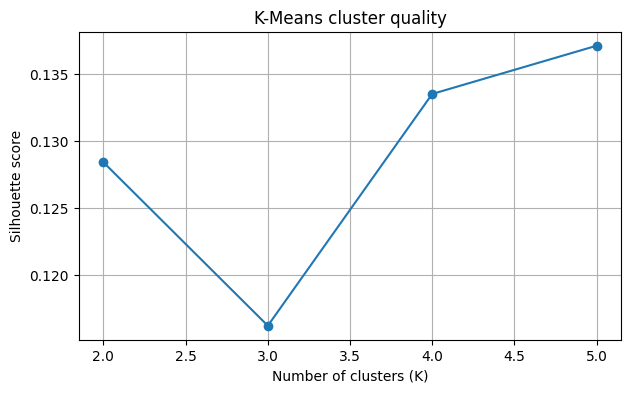

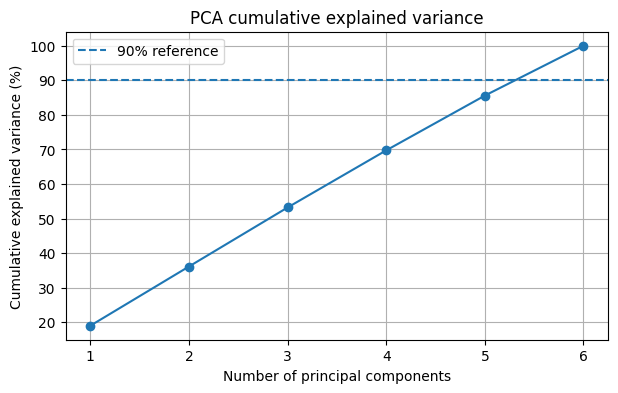

In [2]:
kmeans_results = pd.DataFrame({
    "K": [2, 3, 4, 5],
    "Inertia": [26131.24, 23686.95, 21408.51, 18773.88],
    "Silhouette": [0.1284, 0.1162, 0.1335, 0.1371]
})
display(kmeans_results)

plt.figure(figsize=(7, 4))
plt.plot(kmeans_results["K"], kmeans_results["Silhouette"], marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette score")
plt.title("K-Means cluster quality")
plt.grid(True)
plt.show()

pca_variance = [18.98, 17.13, 17.08, 16.53, 15.85, 14.43]
plt.figure(figsize=(7, 4))
plt.plot(range(1, 7), pd.Series(pca_variance).cumsum(), marker="o")
plt.axhline(90, linestyle="--", label="90% reference")
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance (%)")
plt.title("PCA cumulative explained variance")
plt.xticks(range(1, 7))
plt.legend()
plt.grid(True)
plt.show()

### Interpretation of Unit 3

- K-Means inertia decreases as K increases, which is expected; it does not by itself prove that a larger K is better.
- Silhouette scores are low (about 0.12–0.14), suggesting substantial overlap or weakly separated clusters.
- GMM's silhouette score (0.1597) is slightly higher than the tested K-Means scores, but it is still low. Treat this as a modest result, not evidence of strong natural clusters.
- PCA did not achieve a 90% variance reduction with fewer than all six selected components.
- Low factor communalities suggest that the selected variables do not form a strong two-factor structure in this experiment.

## 4. Entered results from Unit 4 – Markov Chain and HMM

- Daily observations: 365
- Training observations: 292
- Testing observations: 73
- Markov next-symbol accuracy: 63.89%
- Baum–Welch iterations: 97
- Final HMM training log-likelihood: -257.4677
- Held-out HMM log-likelihood: -73.006
- Mean test log-likelihood per day: -1.0001
- The Forward and Backward algorithms calculated sequence/posterior probabilities.
- The Viterbi algorithm decoded the most likely hidden-state sequence.

The hidden states represent latent statistical regimes inferred from the daily sequence. They are not verified real-world causes of delay.

In [3]:
unit4_summary = pd.DataFrame({
    "Measure": [
        "Daily observations", "Training observations", "Testing observations",
        "Markov next-symbol accuracy (%)", "Baum-Welch iterations",
        "Final training log-likelihood", "Held-out HMM log-likelihood",
        "Mean test log-likelihood per day"
    ],
    "Value": [365, 292, 73, 63.89, 97, -257.4677, -73.006, -1.0001]
})
display(unit4_summary)

,Measure,Value
0,Daily observations,365.0000
1,Training observations,292.0000
2,Testing observations,73.0000
3,Markov next-symbol accuracy (%),63.8900
4,Baum-Welch iterations,97.0000
5,Final training log-likelihood,-257.4677
6,Held-out HMM log-likelihood,-73.0060
7,Mean test log-likelihood per day,-1.0001


## 5. Overall comparison – compare within task type

| Task | Algorithms / methods | Main evidence | Finding |
|---|---|---|---|
| Regression | MLE, Huber, Ridge, Bayesian Linear | MAE, RMSE, R² | Huber had lowest MAE, but weak R² across models |
| Classification | Gaussian, Logistic, Bayesian Logistic, RBF SVM | Precision, recall, F1, accuracy | Severe class-imbalance / threshold issues |
| Clustering | K-Means, GMM, hierarchical | Inertia, silhouette | Weak cluster separation |
| Dimensionality reduction | PCA, Factor Analysis | Explained variance, communalities | Limited compression / weak factor structure |
| Sequence modelling | Markov chain, HMM | Accuracy, log-likelihood, decoded states | Sequential patterns were modelled successfully; predictive strength needs further validation |

Do not compare an F1 score directly with a silhouette score or a log-likelihood. They answer different questions.

## 6. Important methodological corrections and limitations

1. **Target leakage:** `DEPARTURE_DELAY` is not available before departure. If it is used to predict arrival delay, describe the task as an in-day estimator, not a pre-departure forecast. Post-departure delay-cause fields must also be excluded from a genuine pre-departure model.
2. **HMM threshold leakage:** the earlier Unit 4 notebook calculated delay-category tertile cut points using the full daily sequence before the chronological split. For strict evaluation, calculate cut points on training days only and apply them unchanged to test days.
3. **Classification imbalance:** report the positive-class precision, recall and F1, confusion matrix and class distribution. Do not rely on accuracy alone.
4. **Fair comparison:** models should use the same train/test split, feature set and evaluation records wherever possible. Disclose any model trained on a subset.
5. **Cancellation target:** the current recorded results do not establish a separate cancellation-prediction experiment. Do not claim cancellation prediction was evaluated unless a cancellation label and its metrics are actually implemented.
6. **Sampling:** Unit 3 used 5,000 rows for major analyses and 300 rows for hierarchical clustering. State this clearly in the report.

## 7. Final project conclusion (draft)

The Flight Delay and Cancellation Prediction System explored several mathematical and machine-learning approaches across regression, classification, clustering, dimensionality reduction and sequential modelling. Unit 2 implemented regression and classification algorithms from mathematical principles. The regression results showed limited explanatory performance, while classification results highlighted the challenge of class imbalance and threshold selection. Unit 3 applied K-Means, Gaussian Mixture Models, hierarchical clustering, PCA and Factor Analysis; the low silhouette scores indicated weakly separated groups, and PCA showed limited dimensionality reduction for the selected variables. Unit 4 implemented Markov Chains and Hidden Markov Models with Forward, Backward, Baum–Welch and Viterbi algorithms to analyse daily delay regimes. Overall, the experiments demonstrate the application and comparison of multiple modelling techniques, while also identifying improvements required for reliable real-world prediction.

**Be accurate in your final presentation:** describe this as an experimental prototype. The current recorded results do not yet establish a production-ready predictor or a separately validated cancellation model.